# TP 2 — Classification d'images : ANN puis CNN
**Chapitre 1 · Fondements de l'IA générative** — durée indicative : 2 h

Jeu de données : **Fashion-MNIST** (70 000 images 28×28, 10 classes de vêtements).

Objectifs :
1. Utiliser `Dataset`, `DataLoader` et un découpage entraînement / validation / test.
2. Écrire une boucle d'entraînement et d'évaluation réutilisable.
3. Comparer un réseau dense (ANN) et un réseau convolutif (CNN).
4. Lutter contre le surapprentissage : Dropout, weight decay, arrêt précoce.

In [4]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
DATA_DIR = "./data"

PyTorch 2.14.1 | device : mps


## 1. Données

In [7]:
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
full_train = datasets.FashionMNIST(DATA_DIR, train=True,  download=True, transform=tf)
test_set   = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=tf)

n_val = len(full_train) // 6
train_set, val_set = random_split(full_train, [len(full_train) - n_val, n_val],
                                  generator=torch.Generator().manual_seed(0))
BATCH = 128
train_dl = DataLoader(train_set, batch_size=BATCH, shuffle=True)
val_dl   = DataLoader(val_set,   batch_size=512)
test_dl  = DataLoader(test_set,  batch_size=512)
CLASSES = ["T-shirt", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Basket", "Sac", "Bottine"]
print(len(train_set), len(val_set), len(test_set))

50000 10000 10000


torch.Size([128, 1, 28, 28]) torch.Size([128])


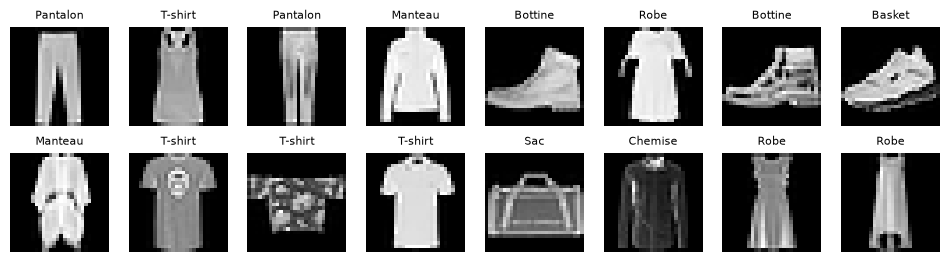

In [8]:
xb, yb = next(iter(train_dl))
print(xb.shape, yb.shape)            # (B, 1, 28, 28), (B,)
fig, ax = plt.subplots(2, 8, figsize=(12, 3))
for i, a in enumerate(ax.flat):
    a.imshow(xb[i, 0], cmap="gray"); a.set_title(CLASSES[yb[i]], fontsize=8); a.axis("off")
plt.show()

**Question.** Pourquoi le jeu de validation est-il séparé du jeu de test ? Que se passerait-il si on choisissait les hyperparamètres sur le jeu de test ?

## 2. Boucle d'entraînement réutilisable

In [9]:
def run_epoch(model, loader, loss_fn, opt=None):
    """Une passe sur loader. Entraîne si opt est fourni, sinon évalue."""
    train = opt is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = loss_fn(logits, y)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(y)
            correct  += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return tot_loss / n, correct / n

def fit(model, epochs=10, lr=1e-3, wd=0.0, patience=3, ckpt="best.pt"):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.CrossEntropyLoss()
    hist, best, wait = [], float("inf"), 0
    for ep in range(1, epochs + 1):
        tr = run_epoch(model, train_dl, loss_fn, opt)
        va = run_epoch(model, val_dl, loss_fn)
        hist.append((tr, va))
        print(f"ep {ep:2d} | train loss {tr[0]:.3f} acc {tr[1]:.3f} | val loss {va[0]:.3f} acc {va[1]:.3f}")
        if va[0] < best:                       # arrêt précoce sur la perte de validation
            best, wait = va[0], 0
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
            if wait >= patience:
                print("Arrêt précoce"); break
    model.load_state_dict(torch.load(ckpt, map_location=device))
    return hist

def plot_hist(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for k, name in enumerate(["loss", "accuracy"]):
        ax[k].plot([h[0][k] for h in hist], label="train")
        ax[k].plot([h[1][k] for h in hist], label="val")
        ax[k].set_title(f"{title} — {name}"); ax[k].legend()
    plt.show()

## 3. Réseau dense (ANN)

235146 paramètres
ep  1 | train loss 0.536 acc 0.807 | val loss 0.422 acc 0.845
ep  2 | train loss 0.384 acc 0.861 | val loss 0.365 acc 0.864
ep  3 | train loss 0.340 acc 0.876 | val loss 0.392 acc 0.854
ep  4 | train loss 0.315 acc 0.884 | val loss 0.361 acc 0.868
ep  5 | train loss 0.294 acc 0.892 | val loss 0.329 acc 0.878
ep  6 | train loss 0.280 acc 0.895 | val loss 0.337 acc 0.881
ep  7 | train loss 0.263 acc 0.903 | val loss 0.321 acc 0.881
ep  8 | train loss 0.250 acc 0.906 | val loss 0.320 acc 0.886
ep  9 | train loss 0.237 acc 0.913 | val loss 0.317 acc 0.887
ep 10 | train loss 0.227 acc 0.915 | val loss 0.326 acc 0.885


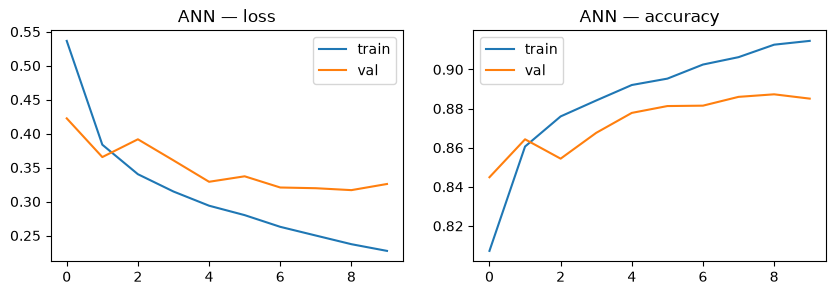

In [10]:
class ANN(nn.Module):
    def __init__(self, p_drop=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28*28, 256), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(256, 128),   nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(128, 10))       # logits : pas de softmax (inclus dans CrossEntropyLoss)
    def forward(self, x):
        return self.net(x)

ann = ANN()
print(sum(p.numel() for p in ann.parameters()), "paramètres")
hist_ann = fit(ann, epochs=10, ckpt="ann.pt")
plot_hist(hist_ann, "ANN")

## 4. Réseau convolutif (CNN)

421834 paramètres
ep  1 | train loss 0.430 acc 0.844 | val loss 0.325 acc 0.877
ep  2 | train loss 0.302 acc 0.889 | val loss 0.271 acc 0.899
ep  3 | train loss 0.268 acc 0.902 | val loss 0.274 acc 0.896
ep  4 | train loss 0.242 acc 0.910 | val loss 0.244 acc 0.908
ep  5 | train loss 0.221 acc 0.919 | val loss 0.246 acc 0.910
ep  6 | train loss 0.205 acc 0.924 | val loss 0.227 acc 0.915
ep  7 | train loss 0.197 acc 0.927 | val loss 0.227 acc 0.914
ep  8 | train loss 0.182 acc 0.932 | val loss 0.231 acc 0.914
ep  9 | train loss 0.171 acc 0.935 | val loss 0.218 acc 0.918
ep 10 | train loss 0.162 acc 0.939 | val loss 0.217 acc 0.920


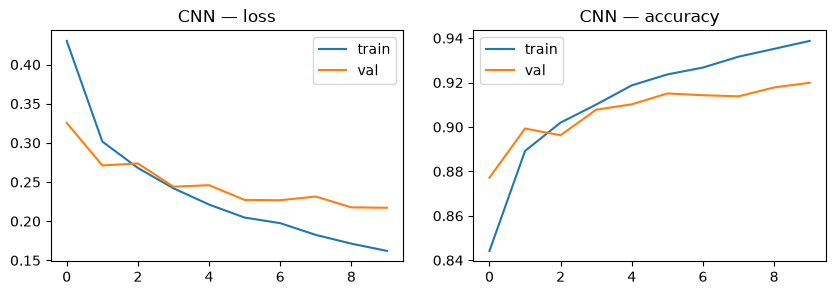

In [11]:
class CNN(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 32×14×14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))  # 64×7×7
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop),
                                  nn.Linear(64*7*7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.head(self.features(x))

cnn = CNN()
print(sum(p.numel() for p in cnn.parameters()), "paramètres")
hist_cnn = fit(cnn, epochs=10, wd=1e-4, ckpt="cnn.pt")
plot_hist(hist_cnn, "CNN")

## 5. Évaluation finale sur le jeu de test

ANN : test acc = 0.880
CNN : test acc = 0.916


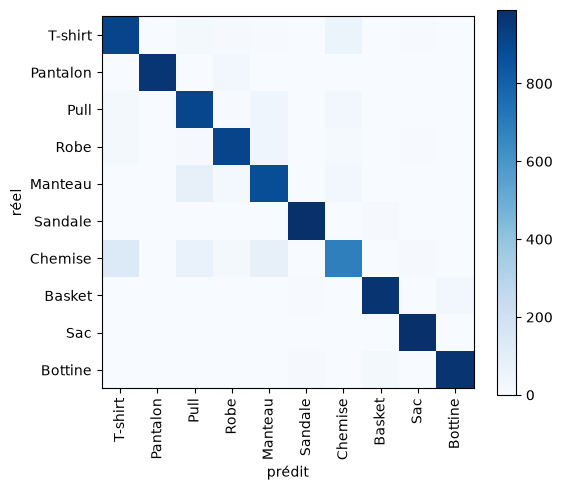

In [12]:
loss_fn = nn.CrossEntropyLoss()
for name, m in [("ANN", ann), ("CNN", cnn)]:
    l, a = run_epoch(m, test_dl, loss_fn)
    print(f"{name} : test acc = {a:.3f}")

# Matrice de confusion du CNN
conf = torch.zeros(10, 10, dtype=torch.long)
cnn.eval()
with torch.no_grad():
    for x, y in test_dl:
        p = cnn(x.to(device)).argmax(1).cpu()
        for t, q in zip(y, p): conf[t, q] += 1
plt.figure(figsize=(6, 5)); plt.imshow(conf, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=90); plt.yticks(range(10), CLASSES)
plt.xlabel("prédit"); plt.ylabel("réel"); plt.colorbar(); plt.show()

## Exercices
1. **Surapprentissage.** Entraînez l'ANN 30 époques sans Dropout (`patience=100`), puis avec `p_drop=0.3`. Décrivez l'écart train/val dans les deux cas.
2. **Analyse d'erreurs.** Quelles paires de classes le CNN confond-il le plus ? Affichez 8 images mal classées.
3. **Architecture.** Ajoutez un troisième bloc convolutif. Le gain justifie-t-il le surcoût en paramètres et en temps ?
4. **Chargement.** Rechargez `cnn.pt` dans un nouveau modèle et vérifiez que la précision de test est identique.

In [ ]:
# À compléter